# Setup

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
%matplotlib ipympl
from Util.util import load_keypoints_and_labels,angle_between_vectors
from Util.pulltest_util import get_axis_velocity
from scipy.signal import find_peaks

loaded data from: data\tug1\tug1_stereo.npz with keys: ['labels', 'keypoints']
loaded data from: data\tug1\tug1_qualisys.npz with keys: ['labels', 'keypoints']


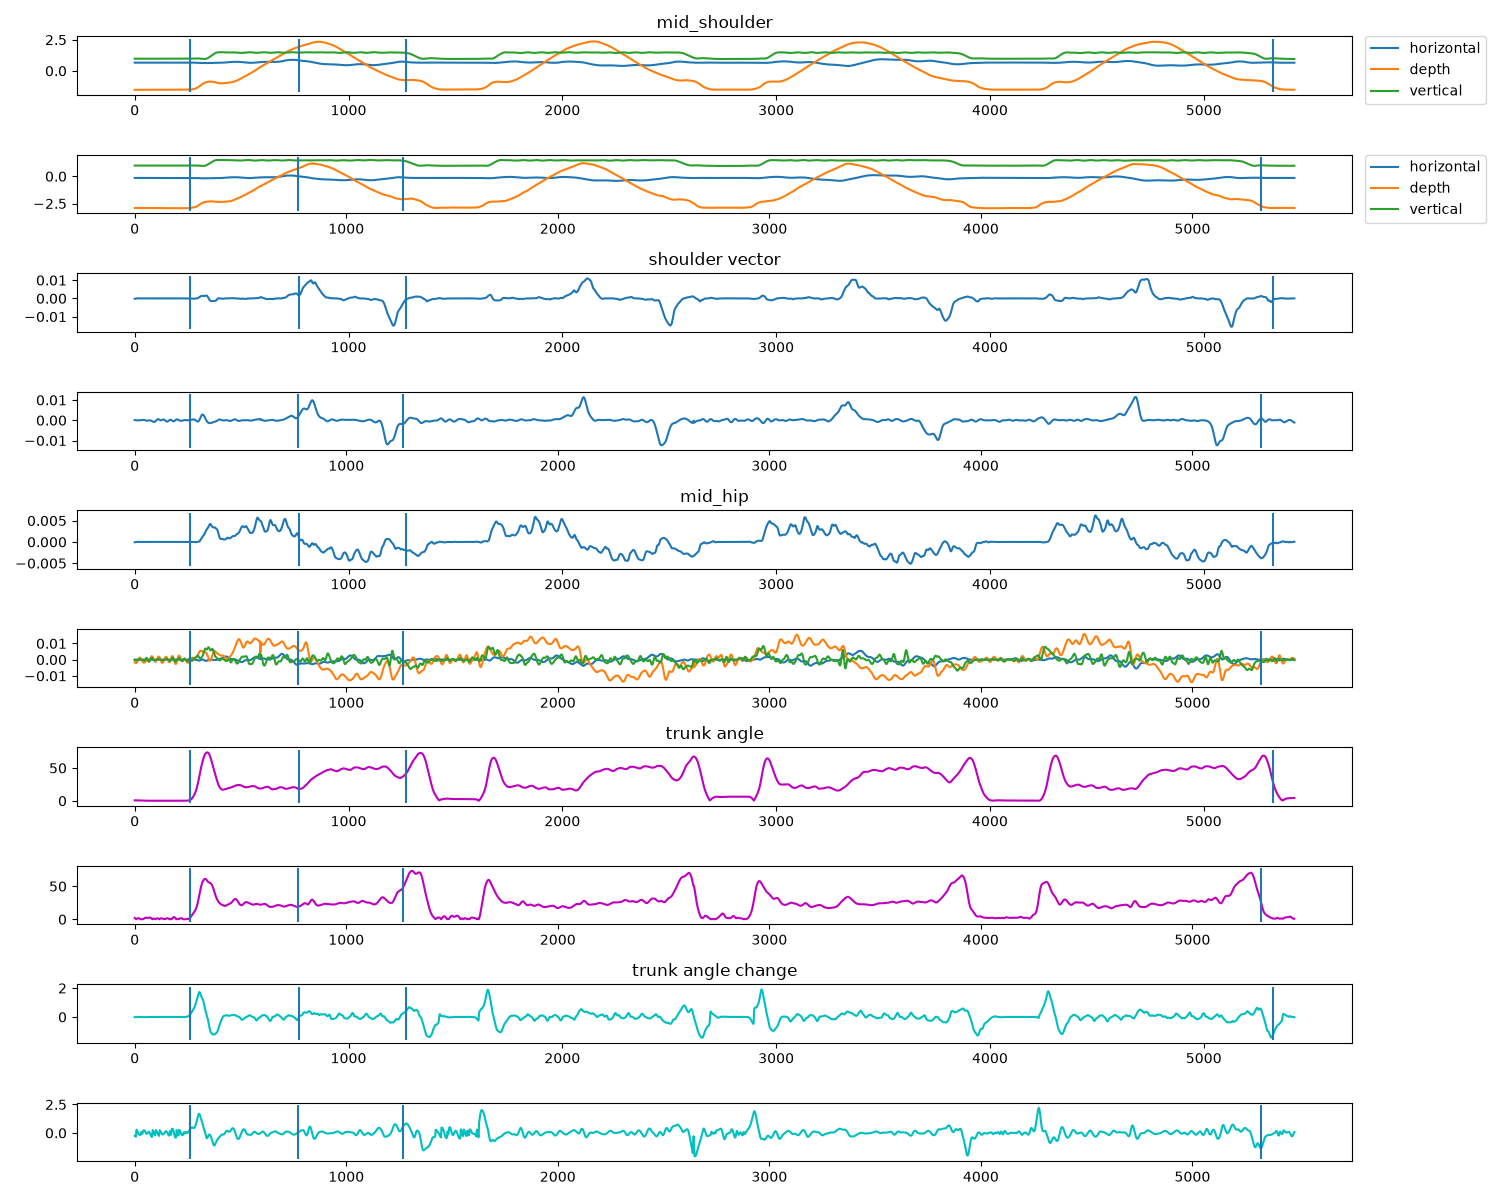

In [25]:
recording_name = "tug1"
filename_stereo = os.path.join("data", recording_name, recording_name + "_stereo.npz")
filename_qualisys = os.path.join("data", recording_name, recording_name + "_qualisys.npz")
stereo_keypoints, stereo_labels = load_keypoints_and_labels(filename=filename_stereo)
qualisys_keypoints, qualisys_labels = load_keypoints_and_labels(filename=filename_qualisys)

q_cut_1 = 775
q_cut_2 = 6200
s_cut_1 = 980
baseline_end = 260
fps = 100

qualisys_keypoints = qualisys_keypoints[q_cut_1:q_cut_2,:,:]
stereo_keypoints = stereo_keypoints[s_cut_1:,:,:]

qualisys_shoulder_vector = np.gradient(qualisys_keypoints[:,qualisys_labels.index('left_shoulder'),0]-qualisys_keypoints[:,qualisys_labels.index('right_shoulder'),0], axis=0)
stereo_shoulder_vector = np.gradient(stereo_keypoints[:,stereo_labels.index('left_shoulder'),0]-stereo_keypoints[:,stereo_labels.index('right_shoulder'),0], axis=0)

qualisys_mid_hip = np.nanmean(np.gradient(qualisys_keypoints[:,qualisys_labels.index('mid_hip'),:],axis=0), axis=1)
stereo_mid_hip = np.gradient(stereo_keypoints[:,stereo_labels.index('mid_hip'),:],axis=0)

qualisys_trunk = qualisys_keypoints[:,qualisys_labels.index("mid_shoulder"),:] - qualisys_keypoints[:, qualisys_labels.index("mid_hip"),:]
stereo_trunk = stereo_keypoints[:,stereo_labels.index("mid_shoulder"),:] - stereo_keypoints[:, stereo_labels.index("mid_hip"),:]

stereo_baseline_trunk = np.nanmean(stereo_trunk[:baseline_end], axis=0)
qualisys_baseline_trunk = np.nanmean(qualisys_trunk[:baseline_end], axis=0)

stereo_trunk_angle = np.array([angle_between_vectors(trunk_vector, stereo_baseline_trunk) for trunk_vector in stereo_trunk])
qualisys_trunk_angle = np.array([angle_between_vectors(trunk_vector, qualisys_baseline_trunk) for trunk_vector in qualisys_trunk])
stereo_trunk_angle_change = np.gradient(stereo_trunk_angle)
qualisys_trunk_angle_change = np.gradient(qualisys_trunk_angle)


plt.close('all')
fig, axs = plt.subplots(10,1,figsize=(15,12))
axs[0].set_title('mid_shoulder')
axs[0].plot(qualisys_keypoints[:,qualisys_labels.index('mid_shoulder'),:], label=['horizontal','depth','vertical'])
axs[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)
axs[1].plot(stereo_keypoints[:,stereo_labels.index('mid_shoulder'),:], label=['horizontal','depth','vertical'])
axs[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)

axs[2].set_title('shoulder vector')
axs[2].plot(qualisys_shoulder_vector)
axs[3].plot(stereo_shoulder_vector)

axs[4].set_title('mid_hip')
axs[4].plot(qualisys_mid_hip)
axs[5].plot(stereo_mid_hip)

axs[6].set_title('trunk angle')
axs[6].plot(qualisys_trunk_angle,'m')
axs[7].plot(stereo_trunk_angle,'m')

axs[8].set_title("trunk angle change")
axs[8].plot(qualisys_trunk_angle_change,'c')
axs[9].plot(stereo_trunk_angle_change,'c')

for ax in axs:
    y_min, y_max = ax.get_ylim()
    ax.vlines(260, y_min, y_max)

    ax.vlines(770, y_min, y_max)
    ax.vlines(1270, y_min, y_max)
    ax.vlines(5325, y_min, y_max)

plt.tight_layout()